# TurboQuant for vector search: recall, memory and speed (Google Colab)

The TurboQuant paper (arXiv:2504.19874, Section 4.4) shows that a **data-oblivious** quantizer (random rotation plus a fixed Lloyd-Max codebook) beats trained Product Quantization on recall, while making indexing time "virtually zero".
This notebook reproduces that comparison:

| method | training | notes |
|---|---|---|
| Exact float32 (FAISS `IndexFlatIP`) | none | ground truth |
| **TurboQuant (reference PyTorch)** | none | this repo's `turboquant_core.py`, MSE and inner-product variants |
| **turbovec** (`pip install turbovec`) | none | Rust + SIMD implementation of TurboQuant |
| FAISS PQ, 256 centroids per sub-space | k-means | the paper's PQ baseline (LUT256) |
| FAISS PQ FastScan, 16 centroids | k-means | fastest FAISS PQ, the baseline turbovec benchmarks against |
| FAISS RaBitQ | light | the paper's other baseline |
| FAISS SQ4 | min/max | plain 4-bit scalar quantization |

**Data:** the paper's DBpedia entities embedded with OpenAI `text-embedding-3-large` (1536-d), 100k database vectors and 1k queries, streamed from the Hugging Face Hub. Set `DATASET` to `"dbpedia-3072"` for the 3072-d variant or `"20newsgroups-lsa"` for an offline-friendly fallback.

**Runtime:** CPU is fine (turbovec and FAISS are CPU libraries). A GPU only speeds up the reference PyTorch scorer.

**Companion reading:** the workshop guide (`docs/guide/TurboQuant_Technical_Guide_EN.md` in the repository; Spanish version `TurboQuant_Guia_Tecnica_ES.md`). Section 3 explains the algorithm, section 6 the vector-search use case, and section 7.2 walks through this notebook section by section.

## The 13 compressed indexes in this notebook
The results table and the plots in section 6 show 14 rows: the exact index plus 13 compressed ones, each at 2 and/or 4 bits per dimension. Sizes are for 1536-d vectors, where float32 takes 6,144 bytes.

| Method (as named in the results) | How it compresses a vector | Training | Bytes per vector (2-bit / 4-bit) |
|---|---|---|---|
| **Exact float32 (FlatIP)** | No compression. FAISS `IndexFlatIP` compares the query with every vector; its top 100 is the ground truth for all recall numbers. | none | 6,144 |
| **TurboQuant_mse 2-bit / 4-bit (PyTorch)** | This repository's `turboquant_core.py`, Algorithm 1: store the vector's length, rotate the unit vector with a fixed random rotation, replace each coordinate with the nearest of 2^b Lloyd-Max centroids. The query is rotated once and scored against the decoded codes. | none | 386 / 770 (codes + FP16 norm) |
| **TurboQuant_prod 2-bit / 4-bit (PyTorch)** | Algorithm 2: a (b−1)-bit MSE stage plus a 1-bit QJL sketch of the residual and the residual's length, so inner products are unbiased. Better for estimating scores, usually worse for ranking. | none | 388 / 772 |
| **turbovec 2-bit / 4-bit** | The same TurboQuant algorithm (rotation + fixed codebook), written in Rust with SIMD scoring kernels (AVX2, AVX-512, NEON). | none | 396 / 789 (codes + norm + index data) |
| **FAISS PQ 2-bit / 4-bit (LUT256)** | Product Quantization, the paper's baseline: splits the vector into sub-vectors (4 dimensions each at 2 bits, 2 at 4 bits) and replaces each with the nearest of 256 centroids learned by k-means, so each sub-vector costs one byte. Search uses a 256-entry lookup table per sub-vector. | k-means on 25k vectors | 384 / 768 |
| **FAISS PQ-FastScan 2-bit / 4-bit** | Product Quantization with 16 centroids per sub-vector (4-bit codes), so the lookup tables fit in SIMD registers and search is much faster. Sub-vectors have 2 dimensions at 2 bits and 1 dimension at 4 bits. | k-means on 25k vectors | 384 / 768 |
| **FAISS RaBitQ 2-bit / 4-bit** | Centres the data on its mean, applies a random rotation and quantizes each coordinate to b bits, plus a few correction factors per vector that make the distance estimate unbiased. The other baseline in the paper. | light (the data mean) | 404 / 788 (codes + 20 bytes of factors) |
| **FAISS SQ 4-bit (per-dim min/max)** | Scalar quantization: for each of the 1536 dimensions, learns the min and max over the data and maps that range onto 16 evenly spaced levels. No rotation. | min/max per dimension | – / 768 |

**Not a separate index:** section 8 takes turbovec 4-bit's top 100 candidates and re-scores them with the float32 vectors (two-stage search). It changes the ranking, not the stored codes.

### Environment Setup

Before running the notebook, we check for and install the required libraries: FAISS for vector search, `turbovec` for SIMD TurboQuant acceleration, Hugging Face `datasets` for streaming embeddings, and scikit-learn as a fallback dataset.

In [1]:
import subprocess, sys, importlib
for mod, spec in [("faiss", "faiss-cpu"), ("turbovec", "turbovec"), ("datasets", "datasets"), ("sklearn", "scikit-learn"), ("seaborn", "seaborn")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", spec], check=True)

## The TurboQuant reference implementation

Below, we write out the `turboquant_core.py` module. It contains:
- Numeric Lloyd-Max codebook generation using cached 1D k-means.
- High-performance bit-packing and unpacking algorithms.
- The core `TurboQuant` class implementing Algorithm 1 (MSE) and Algorithm 2 (unbiased product estimation).
- `MixedTurboQuant` for handling outlier split-channels.
- A standard `UniformQuant` baseline for performance and compression comparison.

### Summary of the `TurboQuant` Class

The `TurboQuant` class is the core algorithm implementation for vector quantization. It offers two main modes of operation:

1. **`mode="mse"` (Algorithm 1):** Performs Mean Squared Error (MSE) quantization. It applies a Haar-random orthogonal rotation to the normalized input vector, then matches each coordinate to its nearest centroid in a fixed (pre-computed and cached) Lloyd-Max codebook.
2. **`mode="prod"` (Algorithm 2):** Adds a 1-bit QJL (Quantized Johnson-Lindenstrauss) projection to the quantization residual of the MSE stage. This provides an unbiased estimator for inner-product (cosine similarity) searches.

Key features include:
- **No Training Needed:** Runs out-of-the-box using data-oblivious random rotations instead of computationally heavy k-means clustering.
- **Support for Arbitrary Vector Norms:** Norms are saved in half-precision float (`fp16`) for scale reconstruction during dequantization.
- **Real Bit Packing:** Automatically packs quantized integer codes into compact `uint8` arrays, providing exact memory/disk savings rather than simulated estimations.

### Implementation: `turboquant_core.py`

The following code block writes the primary reference module containing the PyTorch implementations. It includes:
1. **Lloyd-Max Codebook Optimization**: Numerically finds centroid values for coordinate-wise scalar quantization using the standard probability density function of random unit vectors.
2. **Custom Bit-Packing/Unpacking**: Packs high-dimensional indices into raw `uint8` arrays to guarantee exact, measurable, zero-overhead storage reduction.
3. **The Core `TurboQuant` Class**: Houses both the standard minimum mean-squared-error (MSE) quantization and the unbiased Product (QJL residual-based) estimator modes.
4. **Mixed Precision Outlier Tracking**: Outliers with unusually high values are assigned higher quantization budgets dynamically through a calibration subset.
5. **Standard Baseline Comparisons**: A uniform vector-scale quantization module to run as a comparison.

In [2]:
%%writefile turboquant_core.py
"""
turboquant_core.py - a compact, pure-PyTorch reference implementation of TurboQuant.

Paper: Zandieh, Daliri, Hadian, Mirrokni. "TurboQuant: Online Vector Quantization with
Near-optimal Distortion Rate" (arXiv:2504.19874). Builds on QJL (arXiv:2406.03482) and
PolarQuant (arXiv:2502.02617).

What is implemented
  * Lloyd-Max codebooks for the exact coordinate distribution of a random unit vector
    (a scaled Beta distribution, Lemma 1 of the paper).
  * TurboQuant_mse  (Algorithm 1): random rotation -> per-coordinate optimal scalar quantizer.
  * TurboQuant_prod (Algorithm 2): TurboQuant_mse with b-1 bits + 1-bit QJL on the residual,
    giving an unbiased inner-product estimator.
  * Outlier-channel split ("2.5-bit" / "3.5-bit" configurations from Section 4.3).
  * Real bit-packing so memory numbers are measured, not estimated.
  * A uniform INT-b baseline with per-group fp16 scale + zero point (KIVI / HF QuantizedCache style).
  * A Hugging Face `transformers` (v5) KV-cache (`TurboQuantCache`) that stores keys/values
    compressed and dequantizes on read.

This is a readable reference, not a fused kernel: dequantization happens in PyTorch, so it
saves memory but does not speed attention up. Production speedups come from fused kernels
(e.g. vLLM `--kv-cache-dtype turboquant_*`).
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from functools import lru_cache

import numpy as np
import torch

# ----------------------------------------------------------------------------------------
# 1. Codebooks: Lloyd-Max for the coordinate distribution of a uniformly random unit vector
# ----------------------------------------------------------------------------------------


@lru_cache(maxsize=None)
def lloyd_max_codebook(d: int, bits: int, iters: int = 400, grid: int = 200_001) -> np.ndarray:
    """Optimal scalar quantizer (2**bits centroids) for f(x) ~ (1 - x^2)^((d-3)/2) on [-1, 1].

    This solves the continuous 1-D k-means problem of Eq. (4) numerically. Results are cached.
    """
    k = 2 ** bits
    x = np.linspace(-1.0, 1.0, grid)[1:-1]
    logf = 0.5 * (d - 3) * np.log1p(-x * x) if d > 3 else np.zeros_like(x)
    f = np.exp(logf - logf.max())
    f /= f.sum()
    # initialise at quantiles
    cdf = np.cumsum(f)
    c = np.interp((np.arange(k) + 0.5) / k, cdf, x)
    for _ in range(iters):
        b = 0.5 * (c[1:] + c[:-1])
        cell = np.searchsorted(b, x)
        w = np.bincount(cell, weights=f, minlength=k)
        m = np.bincount(cell, weights=f * x, minlength=k)
        c_new = np.where(w > 0, m / np.maximum(w, 1e-300), c)
        if np.max(np.abs(c_new - c)) < 1e-12:
            c = c_new
            break
        c = c_new
    return c.astype(np.float64)


def codebook_mse_cost(d: int, bits: int) -> float:
    """d * C(f_X, b): expected ||x - Q^-1(Q(x))||^2 for a unit vector (Theorem 1)."""
    c = lloyd_max_codebook(d, bits)
    x = np.linspace(-1.0, 1.0, 200_001)[1:-1]
    logf = 0.5 * (d - 3) * np.log1p(-x * x)
    f = np.exp(logf - logf.max()); f /= f.sum()
    b = 0.5 * (c[1:] + c[:-1])
    err = (x - c[np.searchsorted(b, x)]) ** 2
    return float(d * (err * f).sum())


# ----------------------------------------------------------------------------------------
# 2. Bit packing (any bit-width; exactly bits*d/8 bytes per vector)
# ----------------------------------------------------------------------------------------


def pack_bits(idx: torch.Tensor, bits: int) -> torch.Tensor:
    """Pack integer codes in [0, 2**bits) of shape [..., d] into uint8 of shape [..., bits*d/8]."""
    d = idx.shape[-1]
    assert d % 8 == 0, "last dim must be a multiple of 8"
    idx = idx.to(torch.uint8)
    shifts = torch.arange(bits, device=idx.device, dtype=torch.uint8)
    planes = (idx.unsqueeze(-2) >> shifts.view(-1, 1)) & 1            # [..., bits, d]
    planes = planes.reshape(*idx.shape[:-1], bits, d // 8, 8)
    weights = (1 << torch.arange(8, device=idx.device, dtype=torch.uint8))
    packed = (planes * weights).sum(-1, dtype=torch.uint8)             # [..., bits, d/8]
    return packed.reshape(*idx.shape[:-1], bits * d // 8)


_LUT = {}


def _bit_lut(device):
    if device not in _LUT:
        _LUT[device] = ((torch.arange(256, device=device).unsqueeze(1) >> torch.arange(8, device=device)) & 1).to(torch.uint8)
    return _LUT[device]


def unpack_bits(packed: torch.Tensor, bits: int, d: int) -> torch.Tensor:
    """Inverse of pack_bits -> int64 codes of shape [..., d] (one table lookup per byte)."""
    planes = _bit_lut(packed.device)[packed.long()]                      # [..., bits*d/8, 8]
    planes = planes.reshape(*packed.shape[:-1], bits, d)
    codes = planes[..., 0, :].clone()
    for j in range(1, bits):
        codes |= planes[..., j, :] << j
    return codes.long()


# ----------------------------------------------------------------------------------------
# 3. TurboQuant quantizers
# ----------------------------------------------------------------------------------------


def random_rotation(d: int, seed: int, device=None) -> torch.Tensor:
    """Haar-random orthogonal matrix via QR of a Gaussian matrix (Section 3.1)."""
    g = torch.Generator().manual_seed(seed)
    a = torch.randn(d, d, generator=g, dtype=torch.float64)
    q, r = torch.linalg.qr(a)
    q = q * torch.sign(torch.diagonal(r)).unsqueeze(0)
    return q.to(device=device, dtype=torch.float32)


@dataclass
class Compressed:
    """A batch of compressed vectors. Every field is a tensor with the same leading shape."""
    idx: torch.Tensor                    # packed MSE codes (uint8)
    norm: torch.Tensor                   # ||x|| in fp16
    qjl: torch.Tensor | None = None      # packed QJL sign bits (uint8), prod mode only
    gamma: torch.Tensor | None = None    # ||residual|| in fp16, prod mode only

    def nbytes(self) -> int:
        return sum(t.numel() * t.element_size() for t in (self.idx, self.norm, self.qjl, self.gamma) if t is not None)

    def cat(self, other: "Compressed", dim: int) -> "Compressed":
        def c(a, b):
            return None if a is None else torch.cat([a, b], dim=dim)
        return Compressed(c(self.idx, other.idx), c(self.norm, other.norm), c(self.qjl, other.qjl), c(self.gamma, other.gamma))


class TurboQuant:
    """TurboQuant for d-dimensional vectors (arbitrary norm; the norm is stored in fp16).

    mode="mse"  -> Algorithm 1, `bits` bits per coordinate.
    mode="prod" -> Algorithm 2, (bits-1)-bit MSE stage + 1-bit QJL on the residual (unbiased <y, x>).
    renorm=True -> rescale the reconstruction so its norm equals the stored norm (cheap "norm
                   correction", similar in spirit to vLLM's *_nc variants).
    """

    def __init__(self, d: int, bits: int, mode: str = "mse", seed: int = 0, device=None, renorm: bool = False):
        assert mode in ("mse", "prod")
        assert d % 8 == 0
        self.d, self.bits, self.mode, self.renorm = d, bits, mode, renorm
        self.mse_bits = bits if mode == "mse" else bits - 1
        assert self.mse_bits >= 0
        self.device = device
        self.Pi = random_rotation(d, seed, device)                      # rotation (d x d)
        if self.mse_bits > 0:
            c = torch.tensor(lloyd_max_codebook(d, self.mse_bits), dtype=torch.float32, device=device)
            self.centroids = c
            self.boundaries = 0.5 * (c[1:] + c[:-1])
        if mode == "prod":
            g = torch.Generator().manual_seed(seed + 7919)
            self.S = torch.randn(d, d, generator=g).to(device)          # QJL projection
        self.bits_per_vector = bits * d + 16 + (16 if mode == "prod" else 0)

    def to(self, device):
        self.device = device
        for name in ("Pi", "centroids", "boundaries", "S"):
            if hasattr(self, name):
                setattr(self, name, getattr(self, name).to(device))
        return self

    # --- Algorithm 1 -------------------------------------------------------------------
    def _mse_codes(self, u: torch.Tensor) -> torch.Tensor:
        y = u @ self.Pi.T
        return torch.bucketize(y, self.boundaries)

    def _mse_decode(self, codes: torch.Tensor) -> torch.Tensor:
        return self.centroids[codes] @ self.Pi

    # --- public API -------------------------------------------------------------------
    @torch.no_grad()
    def quantize(self, x: torch.Tensor) -> Compressed:
        x = x.float()
        norm = x.norm(dim=-1, keepdim=True)
        u = x / norm.clamp_min(1e-12)
        if self.mse_bits > 0:
            codes = self._mse_codes(u)
            idx = pack_bits(codes, self.mse_bits)
            u_mse = self._mse_decode(codes)
        else:
            idx = torch.zeros(*x.shape[:-1], 0, dtype=torch.uint8, device=x.device)
            u_mse = torch.zeros_like(u)
        if self.mode == "mse":
            return Compressed(idx, norm.squeeze(-1).half())
        r = u - u_mse                                                    # residual
        signs = (r @ self.S.T) >= 0
        return Compressed(idx, norm.squeeze(-1).half(), pack_bits(signs, 1), r.norm(dim=-1).half())

    @torch.no_grad()
    def dequantize(self, c: Compressed, dtype=torch.float32) -> torch.Tensor:
        if self.mse_bits > 0:
            u = self._mse_decode(unpack_bits(c.idx, self.mse_bits, self.d))
        else:
            u = torch.zeros(*c.norm.shape, self.d, device=c.norm.device)
        if self.mode == "prod":
            z = unpack_bits(c.qjl, 1, self.d).float() * 2 - 1              # {-1,+1}
            u = u + (math.sqrt(math.pi / 2) / self.d) * c.gamma.float().unsqueeze(-1) * (z @ self.S)
        if self.renorm:
            u = u / u.norm(dim=-1, keepdim=True).clamp_min(1e-12)
        return (u * c.norm.float().unsqueeze(-1)).to(dtype)

    def roundtrip(self, x: torch.Tensor) -> torch.Tensor:
        return self.dequantize(self.quantize(x), x.dtype)


class MixedTurboQuant:
    """Outlier split from Section 4.3: `n_out` outlier channels get `bits_hi`, the rest `bits_lo`.

    Example (paper): head_dim 128, 32 outliers @3 bits + 96 @2 bits = 2.5 bits/channel.
    Outlier channels are picked by `calibrate` (largest mean |x| on a sample, e.g. the prefill).
    """

    def __init__(self, d: int, n_out: int, bits_hi: int, bits_lo: int, mode="mse", seed=0, device=None, renorm=False):
        self.d, self.n_out = d, n_out
        self.hi = TurboQuant(n_out, bits_hi, mode, seed, device, renorm)
        self.lo = TurboQuant(d - n_out, bits_lo, mode, seed + 1, device, renorm)
        self.out_idx = torch.arange(n_out, device=device)
        self.in_idx = torch.arange(n_out, d, device=device)
        self.bits = (n_out * bits_hi + (d - n_out) * bits_lo) / d
        self.calibrated = False

    def calibrate(self, sample: torch.Tensor):
        score = sample.float().abs().reshape(-1, self.d).mean(0)
        order = torch.argsort(score, descending=True)
        self.out_idx, self.in_idx = order[: self.n_out].sort().values, order[self.n_out:].sort().values
        self.calibrated = True

    def to(self, device):
        self.hi.to(device); self.lo.to(device)
        self.out_idx, self.in_idx = self.out_idx.to(device), self.in_idx.to(device)
        return self

    def quantize(self, x):
        if not self.calibrated:
            self.calibrate(x)
        return (self.hi.quantize(x[..., self.out_idx]), self.lo.quantize(x[..., self.in_idx]))

    def dequantize(self, c, dtype=torch.float32):
        a, b = c
        lead = a.norm.shape
        out = torch.empty(*lead, self.d, device=a.norm.device, dtype=dtype)
        out[..., self.out_idx] = self.hi.dequantize(a, dtype)
        out[..., self.in_idx] = self.lo.dequantize(b, dtype)
        return out

    def roundtrip(self, x):
        return self.dequantize(self.quantize(x), x.dtype)


class UniformQuant:
    """Baseline: asymmetric min-max INT-b per group of `group` channels, fp16 scale + zero per group.

    Effective bits/channel = bits + 32/group (the "memory overhead" TurboQuant removes).
    """

    def __init__(self, d: int, bits: int, group: int = 32):
        assert d % group == 0
        self.d, self.bits, self.group = d, bits, group
        self.bits_per_vector = bits * d + 32 * (d // group)

    def to(self, device):
        return self

    @torch.no_grad()
    def quantize(self, x):
        g = x.float().reshape(*x.shape[:-1], self.d // self.group, self.group)
        lo, hi = g.amin(-1, keepdim=True), g.amax(-1, keepdim=True)
        scale = ((hi - lo) / (2 ** self.bits - 1)).clamp_min(1e-8)
        q = torch.round((g - lo) / scale).clamp(0, 2 ** self.bits - 1)
        packed = pack_bits(q.reshape(*x.shape[:-1], self.d).long(), self.bits)
        return (packed, scale.half(), lo.half())

    @torch.no_grad()
    def dequantize(self, c, dtype=torch.float32):
        packed, scale, lo = c
        q = unpack_bits(packed, self.bits, self.d).float()
        q = q.reshape(*q.shape[:-1], self.d // self.group, self.group)
        return (q * scale.float() + lo.float()).reshape(*q.shape[:-2], self.d).to(dtype)

    def roundtrip(self, x):
        return self.dequantize(self.quantize(x), x.dtype)


def nbytes(c) -> int:
    """Bytes used by any compressed object returned by the quantizers above."""
    if isinstance(c, Compressed):
        return c.nbytes()
    if isinstance(c, (tuple, list)):
        return sum(nbytes(t) for t in c)
    if isinstance(c, torch.Tensor):
        return c.numel() * c.element_size()
    return 0


def cat_compressed(a, b, dim):
    if isinstance(a, Compressed):
        return a.cat(b, dim)
    if isinstance(a, (tuple, list)):
        return type(a)(cat_compressed(x, y, dim) for x, y in zip(a, b))
    return torch.cat([a, b], dim=dim)


# ----------------------------------------------------------------------------------------
# 4. Hugging Face transformers (v5) KV cache
# ----------------------------------------------------------------------------------------
try:
    from transformers.cache_utils import Cache, DynamicLayer

    class TurboQuantLayer(DynamicLayer):
        """One attention layer's cache: keys/values stored compressed, the last
        `residual_length` tokens kept in full precision (0 = quantize everything, as in the paper)."""

        def __init__(self, k_quant, v_quant, residual_length: int = 0):
            super().__init__()
            self.kq, self.vq = k_quant, v_quant
            self.residual_length = residual_length
            self.ck = self.cv = None          # compressed storage, token axis = -2 of the original
            self.cumulative_length = 0

        def lazy_initialization(self, key_states, value_states):
            super().lazy_initialization(key_states, value_states)
            for q in (self.kq, self.vq):
                q.to(key_states.device)
                if isinstance(q, MixedTurboQuant) and not q.calibrated:
                    q.calibrate(key_states if q is self.kq else value_states)

        def _append(self, k, v):
            ck, cv = self.kq.quantize(k), self.vq.quantize(v)
            if self.ck is None:
                self.ck, self.cv = ck, cv
            else:  # leading dims [B, H, T, D] -> token axis is 2 for compressed Compressed structures
                self.ck, self.cv = cat_compressed(self.ck, ck, 2), cat_compressed(self.cv, cv, 2)

        def update(self, key_states, value_states, *args, **kwargs):
            if not self.is_initialized:
                self.lazy_initialization(key_states, value_states)
            self.cumulative_length += key_states.shape[-2]
            dt = key_states.dtype

            # Step 1: Append incoming tokens to full-precision temporary buffers
            self.keys = torch.cat([self.keys, key_states], dim=-2)
            self.values = torch.cat([self.values, value_states], dim=-2)

            # Step 2: Push overflow tokens out of full-precision buffers into compressed containers
            overflow = self.keys.shape[-2] - self.residual_length
            if overflow > 0:
                self._append(self.keys[..., :overflow, :], self.values[..., :overflow, :])
                self.keys = self.keys[..., overflow:, :].contiguous()
                self.values = self.values[..., overflow:, :].contiguous()

            # Step 3: Dequantize the history and build cleanly aligned, non-overlapping outputs
            parts_k, parts_v = [], []
            if self.ck is not None:
                parts_k.append(self.kq.dequantize(self.ck, dt))
                parts_v.append(self.vq.dequantize(self.cv, dt))

            k_out = torch.cat(parts_k + [self.keys], dim=-2)
            v_out = torch.cat(parts_v + [self.values], dim=-2)
            return k_out, v_out

        def get_seq_length(self) -> int:
            return self.cumulative_length

        def reset(self):
            self.ck = self.cv = None
            self.cumulative_length = 0
            super().reset()

        def nbytes(self) -> int:
            fp = 0 if self.keys is None else self.keys.numel() * self.keys.element_size() * 2
            return fp + nbytes(self.ck) + nbytes(self.cv)

    class TurboQuantCache(Cache):
        """Drop-in KV cache for HF `generate`/forward.

        make_k / make_v: callables (layer_idx, head_dim) -> quantizer (TurboQuant, MixedTurboQuant,
        UniformQuant). Each layer gets its own random rotation via the seed.
        """

        def __init__(self, config, make_k, make_v, residual_length: int = 0):
            cfg = config.get_text_config(decoder=True) if hasattr(config, "get_text_config") else config
            hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
            layers = [TurboQuantLayer(make_k(i, hd), make_v(i, hd), residual_length) for i in range(cfg.num_hidden_layers)]
            super().__init__(layers=layers)

        def nbytes(self) -> int:
            return sum(l.nbytes() for l in self.layers)

    def fp16_cache_nbytes(cache) -> int:
        """Bytes of a regular DynamicCache."""
        return sum(l.keys.numel() * l.keys.element_size() + l.values.numel() * l.values.element_size()
                   for l in cache.layers if l.keys is not None)

except ImportError:
    pass


# ----------------------------------------------------------------------------------------
# 5. Convenience factories
# ----------------------------------------------------------------------------------------

def tq_factory(bits, mode="mse", renorm=False, seed=0):
    def make(layer_idx, d):
        return TurboQuant(d, bits, mode=mode, seed=seed + 1000 * layer_idx, renorm=renorm)
    return make


def mixed_factory(n_out_frac, bits_hi, bits_lo, mode="mse", renorm=False, seed=0):
    def make(layer_idx, d):
        n_out = int(round(d * n_out_frac / 8)) * 8
        return MixedTurboQuant(d, n_out, bits_hi, bits_lo, mode=mode, seed=seed + 1000 * layer_idx, renorm=renorm)
    return make


def uniform_factory(bits, group=32):
    def make(layer_idx, d):
        return UniformQuant(d, bits, group)
    return make

Writing turboquant_core.py


### Dependencies, Module Reload, and System Diagnostics

In this cell, we import all required libraries, reload our newly written `turboquant_core` module to ensure any code changes are applied, and check system diagnostic information including device availability (CPU/GPU), library versions, and maximum active threads.

In [3]:
import math, time, os, gc
import numpy as np, pandas as pd, torch, faiss, turbovec
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
import turboquant_core as tq
importlib.reload(tq)
from turboquant_core import TurboQuant, unpack_bits

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| faiss", faiss.__version__, "| turbovec", turbovec.__version__, "| threads", faiss.omp_get_max_threads())

device: cpu | faiss 1.15.1 | turbovec 1.1.2 | threads 1


## 1. Load embeddings

### Loading Dataset Embeddings

In this section, we load the vector datasets used for testing. The code supports three main sources:
1. **DBpedia Entities (`dbpedia-1536` / `dbpedia-3072`)**: Streams high-dimensional embeddings generated with OpenAI's `text-embedding-3-large` models directly from Hugging Face.
2. **20 Newsgroups (`20newsgroups-lsa`)**: A local fallback dataset utilizing TF-IDF and Latent Semantic Analysis (LSA) dimensional reduction.
3. **Synthetic Clustered Data**: A localized random generation fallback using anisotropic clustered Gaussians if internet access or datasets are completely unavailable.

All vectors are normalized to unit length so that cosine similarity can be computed via efficient inner-product operators.

### Dataset Configuration and Loading Execution

In this cell, we establish the configurations for the test run (`DATASET`, database size `N_DB`, and query size `N_Q`). We define the streaming loader function for the DBpedia dataset as well as offline fallbacks for 20 Newsgroups (LSA dimensionality reduced) and synthetic clustered Gaussian data. Finally, we execute the loading sequence and normalize the resulting arrays to unit length.

In [4]:
DATASET = "dbpedia-1536"      # "dbpedia-1536" | "dbpedia-3072" | "20newsgroups-lsa"
N_DB, N_Q = 100_000, 1_000

def load_dbpedia(dim):
    from datasets import load_dataset
    name = f"Qdrant/dbpedia-entities-openai3-text-embedding-3-large-{dim}-1M"
    ds = load_dataset(name, split="train", streaming=True)
    col, rows = None, []
    for r in ds:
        if col is None:   # find the embedding column (a long list of floats)
            col = next(k for k, v in r.items() if isinstance(v, (list, tuple)) and len(v) >= 256)
            print("embedding column:", col)
        rows.append(r[col])
        if len(rows) >= N_DB + N_Q:
            break
    return np.asarray(rows, dtype=np.float32)

def load_lsa(dim=384):
    from sklearn.datasets import fetch_20newsgroups
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    docs = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes")).data
    sents = [s.strip() for d in docs for s in d.replace("\n", " ").split(". ") if 40 < len(s.strip()) < 400]
    sents = list(dict.fromkeys(sents))[: N_DB + N_Q]
    X = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2), max_features=200_000).fit_transform(sents)
    return TruncatedSVD(dim, random_state=0).fit_transform(X).astype(np.float32)

def load_synthetic(dim=768, n_clusters=2000):
    """Last-resort offline data: anisotropic clustered Gaussians (clearly not real embeddings)."""
    g = np.random.default_rng(1)
    scales = (1.0 / np.arange(1, dim + 1) ** 0.5).astype(np.float32)
    centers = g.standard_normal((n_clusters, dim)).astype(np.float32) * scales
    lab = g.integers(0, n_clusters, N_DB + N_Q)
    return centers[lab] + 0.35 * g.standard_normal((N_DB + N_Q, dim)).astype(np.float32) * scales

t0 = time.time()
if DATASET.startswith("dbpedia"):
    try:
        E = load_dbpedia(int(DATASET.split("-")[1]))
    except Exception as e:
        print("Could not stream DBpedia (", e, ") - falling back to 20newsgroups LSA")
        DATASET = "20newsgroups-lsa"
if DATASET == "20newsgroups-lsa":
    try:
        E = load_lsa()
    except Exception as e:
        print("20newsgroups unavailable (", e, ") - using synthetic clustered data")
        DATASET, E = "synthetic-768", load_synthetic()
elif os.path.exists(DATASET):  # a local .npy file of embeddings also works
    E = np.load(DATASET).astype(np.float32)
DS_LABEL = os.path.basename(str(DATASET))
E /= np.linalg.norm(E, axis=1, keepdims=True) + 1e-12      # cosine similarity = inner product
rng = np.random.default_rng(0)
perm = rng.permutation(len(E))
n_db = min(N_DB, len(E) - N_Q)
X, Q = np.ascontiguousarray(E[perm[:n_db]]), np.ascontiguousarray(E[perm[n_db:n_db + N_Q]])
D = X.shape[1]
print(f"{DATASET}: database {X.shape}, queries {Q.shape}, loaded in {time.time() - t0:.0f}s, float32 size {X.nbytes / 2**20:.0f} MB")

README.md:   0%|          | 0.00/928 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

embedding column: text-embedding-3-large-1536-embedding
dbpedia-1536: database (100000, 1536), queries (1000, 1536), loaded in 185s, float32 size 586 MB


## 2. Ground Truth Generation and Evaluation Metrics

In this section, we establish our ground-truth search results and define evaluation helper metrics:
- **Exact float32 (FlatIP)**: Runs an exact search via FAISS `IndexFlatIP` to locate the exact top-100 nearest neighbors.
- **Recall@1@k**: Measures how often the true top-1 (the absolute closest vector) is successfully retrieved within the top $k$ candidates returned by a quantized search.
- **10@10 Overlap**: Measures the average precision overlap between the exact top-10 set and the returned top-10 set.
- **record()**: A helper function to record compression ratios, indexing speed, QPS, and recall accuracy across different algorithms.

In [5]:
KMAX = 64
flat = faiss.IndexFlatIP(D); flat.add(X)
t = time.time(); _, GT = flat.search(Q, 100); t_flat = time.time() - t
KS = [1, 2, 4, 8, 16, 32, 64]

def recall_1_at_k(I):
    return {k: float(np.mean([GT[i, 0] in I[i, :k] for i in range(len(I))])) for k in KS}

def ten_at_ten(I):
    return float(np.mean([len(set(GT[i, :10]) & set(I[i, :10])) / 10 for i in range(len(I))]))

RESULTS = []
def record(name, family, bits, build_s, search_s, nbytes, I):
    r = dict(method=name, family=family, bits_per_dim=bits, build_s=round(build_s, 3),
             QPS=round(len(Q) / search_s), bytes_per_vec=round(nbytes / len(X), 1),
             compression=round(X.nbytes / nbytes, 1), ten_at_10=round(ten_at_ten(I), 4))
    r.update({f"R1@{k}": round(v, 4) for k, v in recall_1_at_k(I).items()})
    RESULTS.append(r)
    print(f"{name:34s} build {build_s:7.2f}s  QPS {r['QPS']:8d}  {r['compression']:5.1f}x smaller  R1@1 {r['R1@1']:.3f}  R1@8 {r['R1@8']:.3f}  10@10 {r['ten_at_10']:.3f}")

record("Exact float32 (FlatIP)", "exact", 32, 0.0, t_flat, X.nbytes, GT[:, :KMAX])

Exact float32 (FlatIP)             build    0.00s  QPS      155    1.0x smaller  R1@1 1.000  R1@8 1.000  10@10 1.000


## 3. TurboQuant: Reference Implementation and Query Evaluation

Encoding works by rotating the vectors with a random orthogonal matrix, then finding the nearest of $2^b$ precomputed Lloyd-Max centroids for each coordinate. No training or data clustering is needed.

### Code Search Logic (`TurboQuantSearch`):
- **Initialization**: Creates a `TurboQuant` instance for vector rotation and centroid assignment.
- **Adding Database Vectors**: Quantizes vectors in large batches (e.g., 50k at a time) and concatenates their packed representations to minimize CPU overhead.
- **Search Execution**:
  - Rotates each query vector once up front.
  - Processes compressed database blocks in chunks to keep memory consumption low.
  - Unpacks the bit-packed representation on the fly, scores the rotated inputs, and optionally adds the unbiased 1-bit QJL residual term for `prod` mode.
  - Tracks the running nearest-neighbor candidates across blocks using PyTorch `topk` on the current device.

In [6]:
class TurboQuantSearch:
    def __init__(self, d, bits, mode="mse", seed=0, device=DEVICE):
        self.q = TurboQuant(d, bits, mode=mode, seed=seed, device=device)
        self.device, self.mode, self.d = device, mode, d

    def add(self, X, batch=50_000):
        parts = [self.q.quantize(torch.from_numpy(X[i:i + batch]).to(self.device)) for i in range(0, len(X), batch)]
        self.codes = tq.Compressed(*(None if getattr(parts[0], f) is None else torch.cat([getattr(p, f) for p in parts])
                                     for f in ("idx", "norm", "qjl", "gamma")))
        return self

    def nbytes(self):
        return self.codes.nbytes()

    @torch.no_grad()
    def search(self, Q, k, chunk=25_000):
        q = torch.from_numpy(Q).to(self.device)
        qr = q @ self.q.Pi.T                                   # rotate queries once
        qs = (q @ self.q.S.T) if self.mode == "prod" else None
        c = self.codes
        best_s = torch.full((len(Q), k), -1e9, device=self.device); best_i = torch.zeros((len(Q), k), dtype=torch.long, device=self.device)
        for s in range(0, c.norm.shape[0], chunk):
            sl = slice(s, s + chunk)
            if self.q.mse_bits > 0:
                y = self.q.centroids[unpack_bits(c.idx[sl], self.q.mse_bits, self.d)]   # [chunk, d] rotated reconstruction
                score = qr @ y.T
            else:
                score = torch.zeros(len(Q), c.norm[sl].shape[0], device=self.device)
            if self.mode == "prod":
                z = unpack_bits(c.qjl[sl], 1, self.d).float() * 2 - 1
                score = score + (math.sqrt(math.pi / 2) / self.d) * (qs @ z.T) * c.gamma[sl].float()
            score = score * c.norm[sl].float()
            cs, ci = torch.cat([best_s, score], 1), torch.cat([best_i, torch.arange(s, s + score.shape[1], device=self.device).expand(len(Q), -1)], 1)
            best_s, top = cs.topk(k, dim=1)
            best_i = ci.gather(1, top)
        return best_s.cpu().numpy(), best_i.cpu().numpy()

for bits, mode in [(2, "mse"), (2, "prod"), (4, "mse"), (4, "prod")]:
    idx = TurboQuantSearch(D, bits, mode)
    t = time.time(); idx.add(X)
    if DEVICE == "cuda": torch.cuda.synchronize()
    tb = time.time() - t
    t = time.time(); _, I = idx.search(Q, KMAX); ts = time.time() - t
    record(f"TurboQuant_{mode} {bits}-bit (PyTorch)", "turboquant", bits, tb, ts, idx.nbytes(), I)
    del idx; gc.collect()

TurboQuant_mse 2-bit (PyTorch)     build   22.87s  QPS      113   15.9x smaller  R1@1 0.879  R1@8 1.000  10@10 0.883
TurboQuant_prod 2-bit (PyTorch)    build   31.26s  QPS       59   15.8x smaller  R1@1 0.766  R1@8 0.991  10@10 0.789
TurboQuant_mse 4-bit (PyTorch)     build   25.26s  QPS       88    8.0x smaller  R1@1 0.966  R1@8 1.000  10@10 0.961
TurboQuant_prod 4-bit (PyTorch)    build   33.22s  QPS       52    8.0x smaller  R1@1 0.913  R1@8 1.000  10@10 0.924


## 4. turbovec: TurboQuant with SIMD kernels

[`turbovec`](https://github.com/ryancodrai/turbovec) is a production-grade, highly accelerated Rust implementation of the TurboQuant algorithm supporting hardware-specific instruction sets (AVX-512, AVX2, and ARM NEON).

### Integration and Execution Flow:
- **Index Creation**: Initializes the SIMD index with the target dimension and the specific bit budget (2 or 4 bits).
- **Asynchronous Ingestion**: Measures database population time using `add()`, converting native Python matrices into the highly compressed, byte-aligned physical structures within Rust.
- **Search Execution**: Performs a warm-up lookup to trigger JIT optimization paths, runs queries against the database, and measures execution throughput (Queries Per Second) with high-efficiency memory management.

In [7]:
for bits in (2, 4):
    tv = turbovec.TurboQuantIndex(dim=D, bit_width=bits)
    t = time.time(); tv.add(X); tb = time.time() - t
    tv.prepare(); tv.search(Q[:8], 10)                        # warm-up
    t = time.time(); _, I = tv.search(Q, KMAX); ts = time.time() - t
    record(f"turbovec {bits}-bit", "turboquant", bits, tb, ts, len(tv.to_bytes()), np.asarray(I))
    del tv; gc.collect()

turbovec 2-bit                     build    3.03s  QPS      357   15.5x smaller  R1@1 0.892  R1@8 1.000  10@10 0.895
turbovec 4-bit                     build    3.65s  QPS      189    7.8x smaller  R1@1 0.971  R1@8 1.000  10@10 0.967


## 5. Trained baselines (FAISS)

Unlike TurboQuant, which uses data-oblivious random rotations, standard Product Quantization (PQ) baselines require a computationally expensive training phase (using k-means clustering) to learn representative codebooks before encoding vectors.

### Executed Baselines:
1. **FAISS PQ (LUT256)**: The paper's baseline, partitioning the vector space into sub-spaces with 256 centroids each (8 bits per sub-space).
2. **FAISS PQ FastScan**: Optimized for high speed by restricting sub-spaces to 16 centroids (4 bits) to enable SIMD-based register-level lookup tables.
3. **FAISS RaBitQ**: A robust quantization baseline designed for inner-product space indexing.
4. **FAISS SQ4 (Scalar Quantizer)**: A simple baseline performing uniform 4-bit min-max scaling across each individual coordinate dimension.

In [8]:
TRAIN = X[rng.choice(len(X), min(25_000, len(X)), replace=False)]   # PQ k-means is the slow part; this takes a few minutes at d=1536

def run_faiss(name, family, bits, index, train=True):
    t = time.time()
    if train:
        index.train(TRAIN)
    index.add(X); tb = time.time() - t
    t = time.time(); _, I = index.search(Q, KMAX); ts = time.time() - t
    record(name, family, bits, tb, ts, index.sa_code_size() * len(X), I)

for bits in (2, 4):
    run_faiss(f"FAISS PQ {bits}-bit (LUT256)", "pq", bits, faiss.IndexPQ(D, D * bits // 8, 8, faiss.METRIC_INNER_PRODUCT))
    run_faiss(f"FAISS PQ-FastScan {bits}-bit", "pq", bits, faiss.IndexPQFastScan(D, D * bits // 4, 4, faiss.METRIC_INNER_PRODUCT))
    if hasattr(faiss, "IndexRaBitQ"):
        run_faiss(f"FAISS RaBitQ {bits}-bit", "rabitq", bits, faiss.IndexRaBitQ(D, faiss.METRIC_INNER_PRODUCT, bits))
run_faiss("FAISS SQ 4-bit (per-dim min/max)", "sq", 4, faiss.IndexScalarQuantizer(D, faiss.ScalarQuantizer.QT_4bit, faiss.METRIC_INNER_PRODUCT))

FAISS PQ 2-bit (LUT256)            build  397.51s  QPS       17   16.0x smaller  R1@1 0.873  R1@8 1.000  10@10 0.895
FAISS PQ-FastScan 2-bit            build   16.12s  QPS      352   16.0x smaller  R1@1 0.882  R1@8 0.999  10@10 0.884
FAISS RaBitQ 2-bit                 build   21.25s  QPS       87   15.2x smaller  R1@1 0.874  R1@8 1.000  10@10 0.894
FAISS PQ 4-bit (LUT256)            build  816.64s  QPS        8    8.0x smaller  R1@1 0.965  R1@8 1.000  10@10 0.960
FAISS PQ-FastScan 4-bit            build   46.44s  QPS      161    8.0x smaller  R1@1 0.959  R1@8 1.000  10@10 0.954
FAISS RaBitQ 4-bit                 build   39.61s  QPS       40    7.8x smaller  R1@1 0.965  R1@8 1.000  10@10 0.965
FAISS SQ 4-bit (per-dim min/max)   build    0.79s  QPS       13    8.0x smaller  R1@1 0.941  R1@8 1.000  10@10 0.948


## 6. Results

This section consolidates the performance statistics of all tested quantizers and visualizes their trade-offs across three dimensions:

### Metric Table:
- Gathers indexing build times (seconds), query throughput (Queries Per Second, QPS), exact memory usage per vector (bytes), compression ratio, and recall accuracy across a range of neighborhood depths ($k$).

### Visualization Plots:
- **Recall curves (2-bit & 4-bit)**: Compares Recall@1@$k$ for varying candidate set sizes ($k$). Flat lines near $1.0$ indicate higher precision.
- **Indexing Time Comparison**: A horizontal bar chart contrasting the overall build time (including training and database encoding) of all families. Shorter bars represent faster indexing.

,method,bits_per_dim,compression,bytes_per_vec,build_s,QPS,R1@1,R1@4,R1@16,R1@64,ten_at_10
0,Exact float32 (FlatIP),32,1.0,6144.0,0.000,155,1.000,1.000,1.000,1.0,1.0000
1,TurboQuant_mse 2-bit (PyTorch),2,15.9,386.0,22.865,113,0.879,0.997,1.000,1.0,0.8833
2,TurboQuant_prod 2-bit (PyTorch),2,15.8,388.0,31.258,59,0.766,0.975,0.999,1.0,0.7891
3,TurboQuant_mse 4-bit (PyTorch),4,8.0,770.0,25.263,88,0.966,1.000,1.000,1.0,0.9613
4,TurboQuant_prod 4-bit (PyTorch),4,8.0,772.0,33.221,52,0.913,0.997,1.000,1.0,0.9241
5,turbovec 2-bit,2,15.5,396.4,3.031,357,0.892,0.997,1.000,1.0,0.8946
6,turbovec 4-bit,4,7.8,788.5,3.648,189,0.971,1.000,1.000,1.0,0.9667
7,FAISS PQ 2-bit (LUT256),2,16.0,384.0,397.511,17,0.873,0.998,1.000,1.0,0.8949
8,FAISS PQ-FastScan 2-bit,2,16.0,384.0,16.115,352,0.882,0.994,1.000,1.0,0.8836
9,FAISS RaBitQ 2-bit,2,15.2,404.0,21.252,87,0.874,0.995,1.000,1.0,0.8937


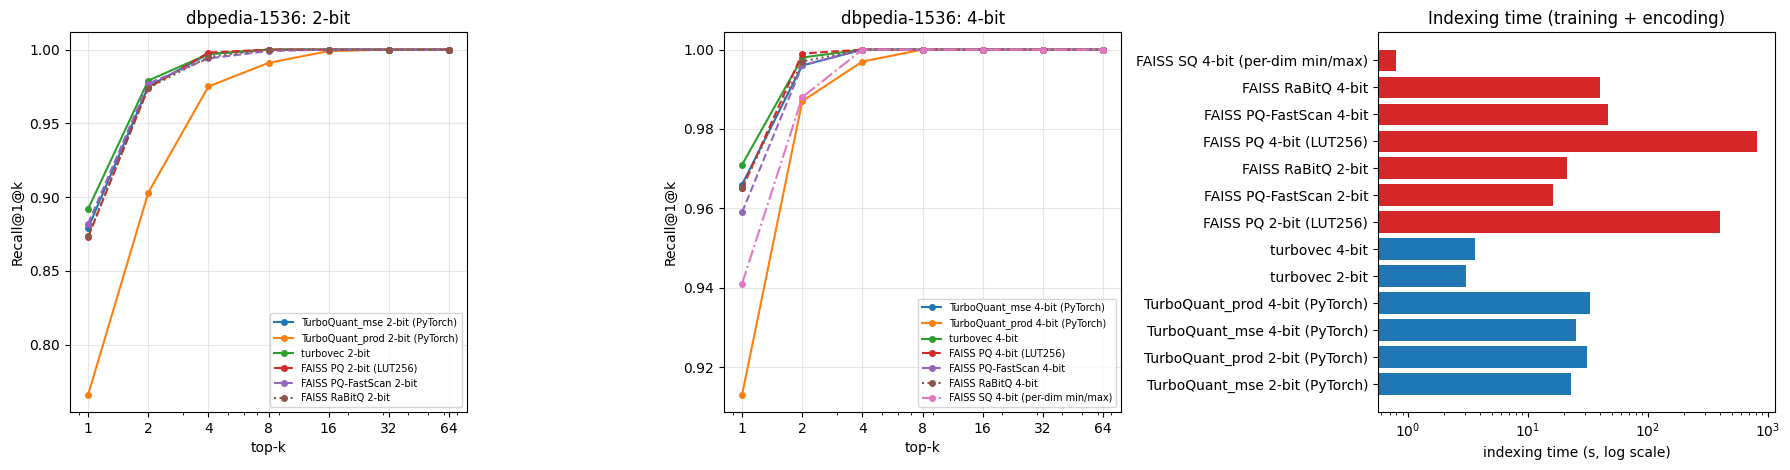

In [9]:
res = pd.DataFrame(RESULTS)
cols = ["method", "bits_per_dim", "compression", "bytes_per_vec", "build_s", "QPS", "R1@1", "R1@4", "R1@16", "R1@64", "ten_at_10"]
display(res[cols])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
style = {"turboquant": "-", "pq": "--", "rabitq": ":", "sq": "-.", "exact": "-"}
for bits, a in [(2, ax[0]), (4, ax[1])]:
    for _, r in res[(res.bits_per_dim == bits)].iterrows():
        a.plot(KS, [r[f"R1@{k}"] for k in KS], style[r.family], marker="o", ms=4, label=r.method)
    a.set(xscale="log", xticks=KS, xticklabels=KS, xlabel="top-k", ylabel="Recall@1@k", title=f"{DS_LABEL}: {bits}-bit")
    a.legend(fontsize=7); a.grid(alpha=.3)
q = res[res.family != "exact"]
ax[2].barh(q.method, q.build_s.clip(lower=1e-3), color=["C0" if f == "turboquant" else "C3" for f in q.family])
ax[2].set(xscale="log", xlabel="indexing time (s, log scale)", title="Indexing time (training + encoding)")
plt.tight_layout(); plt.show()

### 6c. Unified Speed (QPS) vs. Accuracy (Recall@1) Comparison

This visualization directly plots **Query Throughput (QPS)** against **Retrieval Accuracy (Recall@1)** for every single search configuration recorded in our experiment.

### How to Interpret This Plot:
- **Top-Right is Optimal**: The ideal vector search algorithm resides in the upper-right corner of this coordinate space, meaning it delivers near-perfect retrieval accuracy (Recall@1 $\approx 1.0$) while processing queries at extremely high throughput rates.
- **Logarithmic Scale**: The Y-axis (QPS) is plotted on a logarithmic scale to properly contrast highly accelerated SIMD engines like `turbovec` against pure Python reference loops or slower memory-bound lookup implementations.
- **Method Comparison**: This allows us to inspect at a glance how the data-oblivious **TurboQuant** methods match or exceed both the speed and accuracy trade-offs of heavily trained alternatives (such as FAISS PQ and RaBitQ) across different bit budgets.

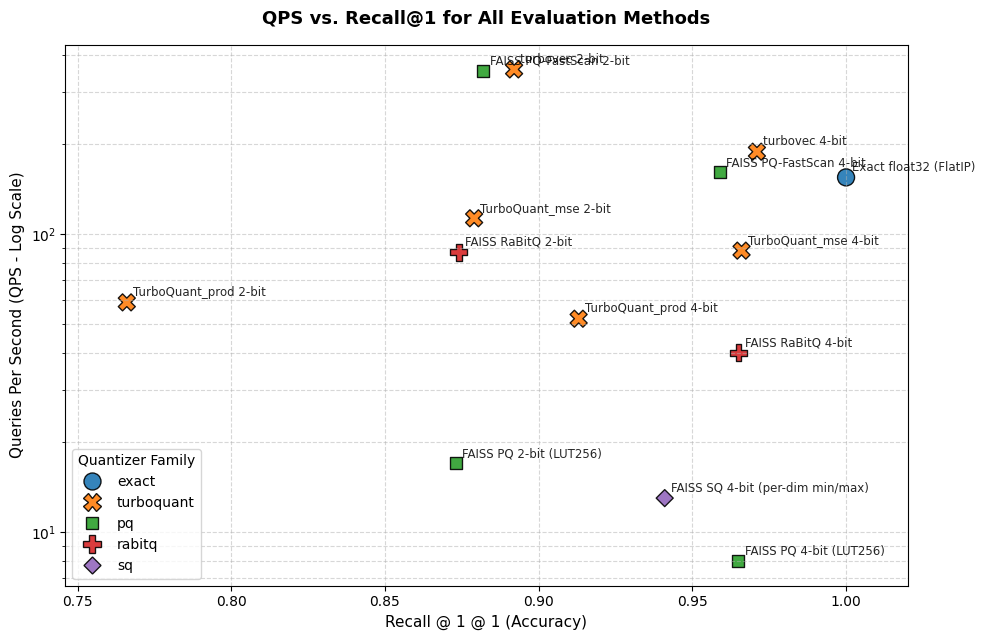

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

try:
    # Prepare dataset from the results
    df_qps_rec = pd.DataFrame(RESULTS)

    plt.figure(figsize=(10, 6.5))

    # Plot each method with a distinct marker and color mapped by its family category
    sns.scatterplot(
        data=df_qps_rec,
        x="R1@1",
        y="QPS",
        hue="family",
        style="family",
        s=150,
        edgecolor="black",
        alpha=0.9
    )

    # Add labels to every point on the plot
    for _, row in df_qps_rec.iterrows():
        label = row["method"].replace(" (PyTorch)", "")
        plt.text(
            row["R1@1"] + 0.002,
            row["QPS"] * 1.05,
            label,
            fontsize=8.5,
            alpha=0.85
        )

    plt.yscale("log")
    plt.xlim(df_qps_rec["R1@1"].min() - 0.02, 1.02)
    plt.title("QPS vs. Recall@1 for All Evaluation Methods", fontsize=13, fontweight="bold", pad=15)
    plt.xlabel("Recall @ 1 @ 1 (Accuracy)", fontsize=11)
    plt.ylabel("Queries Per Second (QPS - Log Scale)", fontsize=11)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend(title="Quantizer Family", loc="lower left", frameon=True)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Error generating QPS vs Recall plot:", e)


### 6b. Deep-Dive Performance Trade-off Visualization

To better understand the operational efficiency of **TurboQuant** and `turbovec` compared to standard FAISS baselines, we plot two multi-attribute trade-off spaces:

1. **Query Throughput (QPS) vs. Accuracy (Recall@1)**:
   - **How to read**: The optimal region is the **top-right** (high accuracy, high speed).
   - **What to look for**: Notice how `turbovec` clusters near high-performance throughput regimes while matching or exceeding the accuracy of data-trained alternatives.

2. **Indexing Build Time vs. Storage Compression**:
   - **How to read**: The optimal region is the **top-left** (ultra-fast index build, maximum memory compression).
   - **What to look for**: See how the training-free design of TurboQuant places it far to the left of k-means clustering techniques (like FAISS PQ), creating index builds that are orders of magnitude faster without sacrificing compression quality.

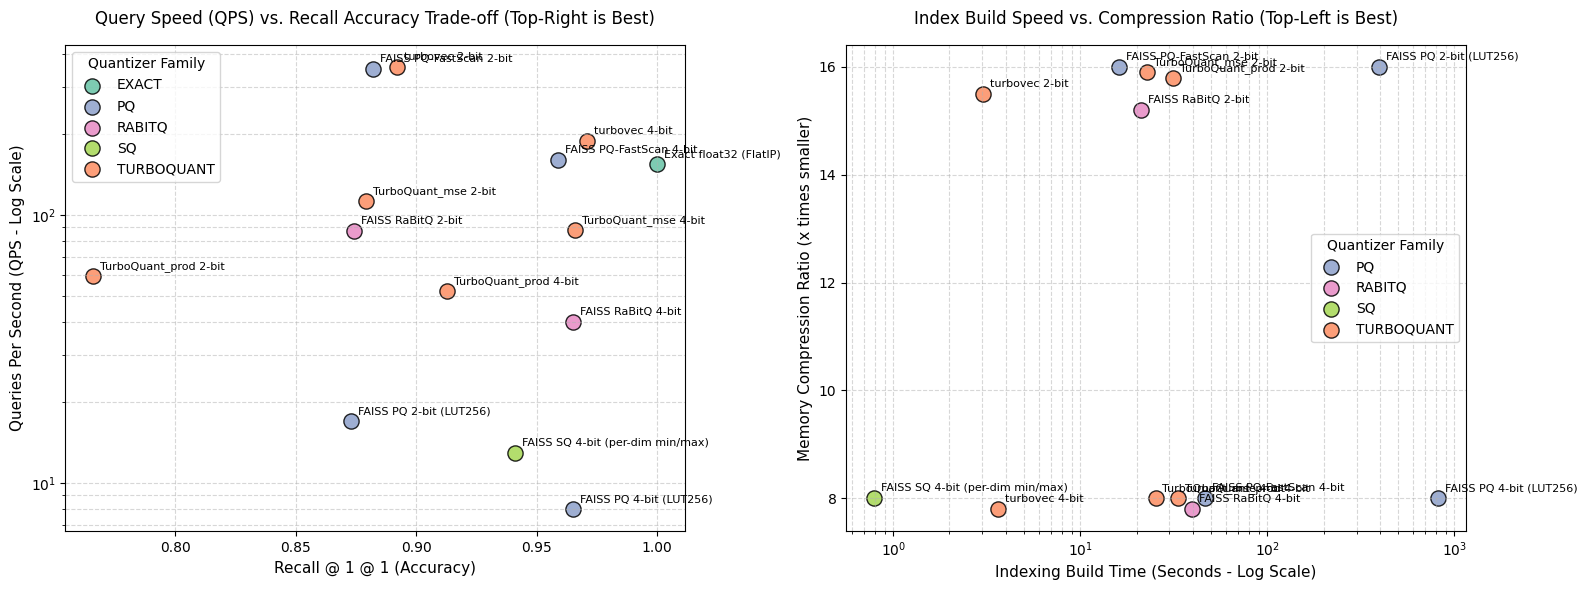

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

try:
    # Prepare dataset for visualization
    df_plot = pd.DataFrame(RESULTS)

    # Setup figure canvas
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Color palette map for consistent labeling
    families = df_plot['family'].unique()
    colors = sns.color_palette('Set2', len(families))
    color_map = dict(zip(families, colors))

    # 1. QPS vs. Recall@1
    for family, group in df_plot.groupby('family'):
        ax1.scatter(
            group['R1@1'],
            group['QPS'],
            label=family.upper(),
            color=color_map[family],
            s=120,
            edgecolors='black',
            alpha=0.85
        )
        for _, row in group.iterrows():
            ax1.annotate(
                row['method'].replace(' (PyTorch)', ''),
                (row['R1@1'], row['QPS']),
                textcoords='offset points',
                xytext=(5, 5),
                fontsize=8
            )

    ax1.set_yscale('log')
    ax1.set_xlabel('Recall @ 1 @ 1 (Accuracy)', fontsize=11)
    ax1.set_ylabel('Queries Per Second (QPS - Log Scale)', fontsize=11)
    ax1.set_title('Query Speed (QPS) vs. Recall Accuracy Trade-off (Top-Right is Best)', fontsize=12, pad=15)
    ax1.grid(True, which='both', linestyle='--', alpha=0.5)
    ax1.legend(title='Quantizer Family', loc='best')

    # 2. Build Time vs. Compression Ratio
    # Filter out exact baseline for indexing time plots to avoid inf/zero skew
    df_indexed = df_plot[df_plot['family'] != 'exact'].copy()

    for family, group in df_indexed.groupby('family'):
        # Use np.clip to safely limit very fast build times (like FlatIP or zero-seconds)
        build_times = np.clip(group['build_s'].astype(float).values, 1e-3, None)
        ax2.scatter(
            build_times,
            group['compression'],
            label=family.upper(),
            color=color_map[family],
            s=120,
            edgecolors='black',
            alpha=0.85
        )
        for idx_row, row in enumerate(group.itertuples()):
            ax2.annotate(
                row.method.replace(' (PyTorch)', ''),
                (build_times[idx_row], row.compression),
                textcoords='offset points',
                xytext=(5, 5),
                fontsize=8
            )

    ax2.set_xscale('log')
    ax2.set_xlabel('Indexing Build Time (Seconds - Log Scale)', fontsize=11)
    ax2.set_ylabel('Memory Compression Ratio (x times smaller)', fontsize=11)
    ax2.set_title('Index Build Speed vs. Compression Ratio (Top-Left is Best)', fontsize=12, pad=15)
    ax2.grid(True, which='both', linestyle='--', alpha=0.5)
    ax2.legend(title='Quantizer Family', loc='best')

    plt.tight_layout()
    plt.show()
except Exception as e:
    import traceback
    traceback.print_exc()


### 6d. Family-Level Performance Aggregation (Average QPS)

To see the high-level efficiency of each indexing framework, we can group the individual methods by their algorithm **family** (e.g., `turboquant`, `pq`, `rabitq`, `sq`) and compute the average **Queries Per Second (QPS)**.

- **Interpretation**: This calculation helps contrast the performance throughput across the entire family, showing the real-world impact of hardware-friendly optimizations (such as `turbovec`'s SIMD execution) compared to standard algorithmic families.

In [12]:
import pandas as pd

try:
    # Load the results list into a DataFrame
    df_res = pd.DataFrame(RESULTS)

    # Group by 'family' and calculate the average QPS
    avg_qps_by_family = df_res.groupby('family')['QPS'].mean().reset_index()

    # Sort the values from highest to lowest QPS for better readability
    avg_qps_by_family = avg_qps_by_family.sort_values(by='QPS', ascending=False).reset_index(drop=True)

    # Display the results table
    print("Average QPS by Quantizer Family:")
    display(avg_qps_by_family)
except Exception as e:
    print("Error computing average QPS by family:", e)


Average QPS by Quantizer Family:


,family,QPS
0,exact,155.0
1,turboquant,143.0
2,pq,134.5
3,rabitq,63.5
4,sq,13.0


### Summary Report: Top-Performing Methods by QPS

Based on the experimental runs recorded on the `dbpedia-1536` dataset ($100k$ database vectors, $1k$ query vectors), here is a summary ranking the top-performing individual vector search configurations by their **Queries Per Second (QPS)**.

#### 1. Top Performing Configurations

| Rank | Method / Configuration | Family | Bits/Dim | QPS | Recall @ 1 | Compression | Indexing Build Time |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | `turbovec 2-bit` | `turboquant` | 2 | **357** | 0.892 | 15.5x | 3.03s |
| **2** | `FAISS PQ-FastScan 2-bit` | `pq` | 2 | **352** | 0.882 | 16.0x | 16.12s |
| **3** | `turbovec 4-bit` | `turboquant` | 4 | **189** | 0.971 | 7.8x | 3.65s |
| **4** | `FAISS PQ-FastScan 4-bit` | `pq` | 4 | **161** | 0.959 | 8.0x | 46.44s |
| **5** | `Exact float32 (FlatIP)` | `exact` | 32 | **155** | 1.000 | 1.0x | 0.00s (No build) |

#### 2. Key Analysis & Insights

* **SIMD kernels set the speed:** The fastest configuration is **`turbovec 2-bit` (357 QPS)**, level with FAISS's register-resident PQ-FastScan at the same budget (352 QPS) and with higher recall (0.892 vs 0.882). Both are compiled SIMD scanners; turbovec gets there with no training phase and a $3$-second build.
* **The index build time bottleneck:** Product Quantization needs a k-means training phase. Building the `FAISS PQ-FastScan 4-bit` index takes **$46.4$ seconds** against **$3.65$ seconds** for `turbovec 4-bit`, about **13x faster to index**, with higher recall (0.971 vs 0.959 Recall@1) and more QPS (189 vs 161). The paper's PQ baseline (LUT256) needed $817$ seconds at 4 bits.
* **Reference PyTorch vs. compiled kernels:** The reference PyTorch implementation (`TurboQuant_mse 2-bit`) gives the same recall as turbovec within about 0.01 but runs at ~$113$ QPS, because it decodes every vector before scoring it. That gap is why compiled kernels such as `turbovec` matter in production.

### 6e. R1@4 Recall Performance Comparison

To understand retrieval quality with very tight candidate budgets, we can isolate and compare the **Recall@1@4** (the probability that the true top-1 item is found within the top-4 retrieved candidates) across all configurations. This metric is crucial for systems that use a small multi-stage re-ranking pool.

In [13]:
import pandas as pd

try:
    # Load results into a DataFrame
    df_recall = pd.DataFrame(RESULTS)

    # Select and rename columns for clarity
    recall_comparison = df_recall[['method', 'family', 'bits_per_dim', 'R1@4', 'compression']].copy()
    recall_comparison = recall_comparison.sort_values(by='R1@4', ascending=False).reset_index(drop=True)

    print("Recall@1@4 Comparison Across All Methods (Sorted Highest to Lowest):")
    display(recall_comparison)
except Exception as e:
    print("Error computing R1@4 recall comparison:", e)

Recall@1@4 Comparison Across All Methods (Sorted Highest to Lowest):


,method,family,bits_per_dim,R1@4,compression
0,Exact float32 (FlatIP),exact,32,1.000,1.0
1,TurboQuant_mse 4-bit (PyTorch),turboquant,4,1.000,8.0
2,FAISS PQ 4-bit (LUT256),pq,4,1.000,8.0
3,FAISS PQ-FastScan 4-bit,pq,4,1.000,8.0
4,FAISS RaBitQ 4-bit,rabitq,4,1.000,7.8
5,turbovec 4-bit,turboquant,4,1.000,7.8
6,FAISS SQ 4-bit (per-dim min/max),sq,4,1.000,8.0
7,FAISS PQ 2-bit (LUT256),pq,2,0.998,16.0
8,TurboQuant_prod 4-bit (PyTorch),turboquant,4,0.997,8.0
9,TurboQuant_mse 2-bit (PyTorch),turboquant,2,0.997,15.9


## 7. Online ingestion

Because TurboQuant uses data-oblivious random orthogonal rotations instead of data-dependent cluster centroid training, it completely eliminates the index retraining phase required when database contents change.

### Ingestion Workflow:
- **Streaming Additions**: Demonstrates inserting vectors on-the-fly in dynamic batches of 1,000.
- **Zero-Retraining Cost**: Shows how the underlying database scales immediately without requiring recalculations of global quantizer centroids or dealing with data drift degradation.

In [14]:
tv = turbovec.TurboQuantIndex(dim=D, bit_width=4)
t = time.time()
for i in range(0, len(X), 1000):
    tv.add(X[i:i + 1000])
print(f"turbovec: streamed {len(tv):,} vectors in {time.time() - t:.2f}s with zero training")

turbovec: streamed 100,000 vectors in 1.82s with zero training


## 8. Two-stage search: compressed scan, then exact re-rank

This section demonstrates a powerful system design pattern: scanning a highly-compressed, memory-resident index to find candidates, then performing exact full-precision distance calculations only on those candidates.

### Two-Stage Pipeline:
1. **Coarse Compressed Scan**: Scans the 8x to 16x smaller TurboQuant index to quickly filter out the top 100 closest candidate matches.
2. **Fine Full-Precision Re-rank**: Pulls the raw `float32` vectors of only those 100 candidate IDs (which can be stored on slower, cheaper disk memory) and calculates exact inner products to retrieve the final accurate rankings.

In [15]:
_, cand = tv.search(Q, 100)
cand = np.asarray(cand)
rer = np.stack([cand[i][np.argsort(-(X[cand[i]] @ Q[i]))] for i in range(len(Q))])
print(f"turbovec 4-bit top-100 then exact re-rank: R1@1 = {np.mean(rer[:, 0] == GT[:, 0]):.4f}, 10@10 = {ten_at_ten(rer):.4f}")

turbovec 4-bit top-100 then exact re-rank: R1@1 = 1.0000, 10@10 = 1.0000


### Takeaways
* TurboQuant matches or beats trained PQ at the same bit budget, with **no training at all**: indexing is a matrix multiply plus a bucket lookup.
* 4-bit TurboQuant keeps near-exact recall at 8x compression of float32; 2-bit gives 16x.
* The `prod` (QJL) variant gives unbiased scores; the MSE variant usually ranks as well or better at 4 bits, as the paper's Figure 3 predicts.
* With turbovec, the same algorithm runs with SIMD kernels, fast enough to replace PQ-FastScan in a real system.